## Phase 1: Loading the data for my project

In [1]:
# Cell 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
# Cell 2: the file has no header, and values are wrapped in single quotes
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/breast-cancer.csv"
COLUMNS = ["age", "menopause", "tumor_size", "inv_nodes", "node_caps",
           "deg_malig", "breast", "breast_quad", "irradiat", "recurrence"]

df = pd.read_csv(URL, header=None, names=COLUMNS, quotechar="'")
print(df.shape)
df.head()

(286, 10)


,age,menopause,tumor_size,inv_nodes,node_caps,deg_malig,breast,breast_quad,irradiat,recurrence
0,40-49,premeno,15-19,0-2,yes,3,right,left_up,no,recurrence-events
1,50-59,ge40,15-19,0-2,no,1,right,central,no,no-recurrence-events
2,50-59,ge40,35-39,0-2,no,2,left,left_low,no,recurrence-events
3,40-49,premeno,35-39,0-2,yes,3,right,left_low,yes,no-recurrence-events
4,40-49,premeno,30-34,3-5,yes,2,left,right_up,no,recurrence-events


## Phase 2: Understanding the data

In [3]:
# Cell 3
df["deg_malig"] = df["deg_malig"].astype(str)
df.info()
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          286 non-null    object
 1   menopause    286 non-null    object
 2   tumor_size   286 non-null    object
 3   inv_nodes    286 non-null    object
 4   node_caps    278 non-null    object
 5   deg_malig    286 non-null    object
 6   breast       286 non-null    object
 7   breast_quad  285 non-null    object
 8   irradiat     286 non-null    object
 9   recurrence   286 non-null    object
dtypes: object(10)
memory usage: 22.5+ KB
age            0
menopause      0
tumor_size     0
inv_nodes      0
node_caps      8
deg_malig      0
breast         0
breast_quad    1
irradiat       0
recurrence     0
dtype: int64
Duplicate rows: 14


,0
age,6
menopause,3
tumor_size,11
inv_nodes,7
node_caps,2
deg_malig,3
breast,2
breast_quad,5
irradiat,2
recurrence,2


recurrence
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64
recurrence
no-recurrence-events    0.703
recurrence-events       0.297
Name: proportion, dtype: float64


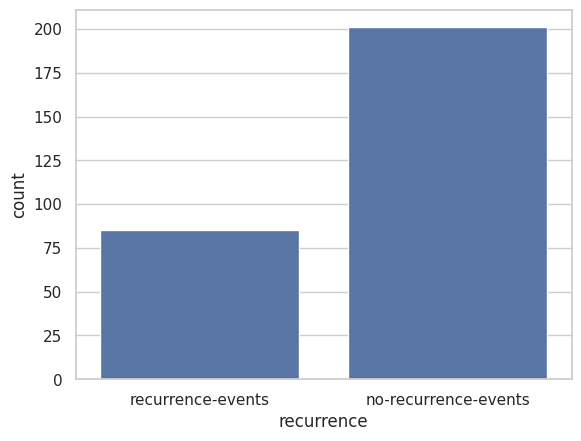

In [4]:
# Cell 4
print(df["recurrence"].value_counts())
print(df["recurrence"].value_counts(normalize=True).round(3))
sns.countplot(x="recurrence", data=df)
plt.show()

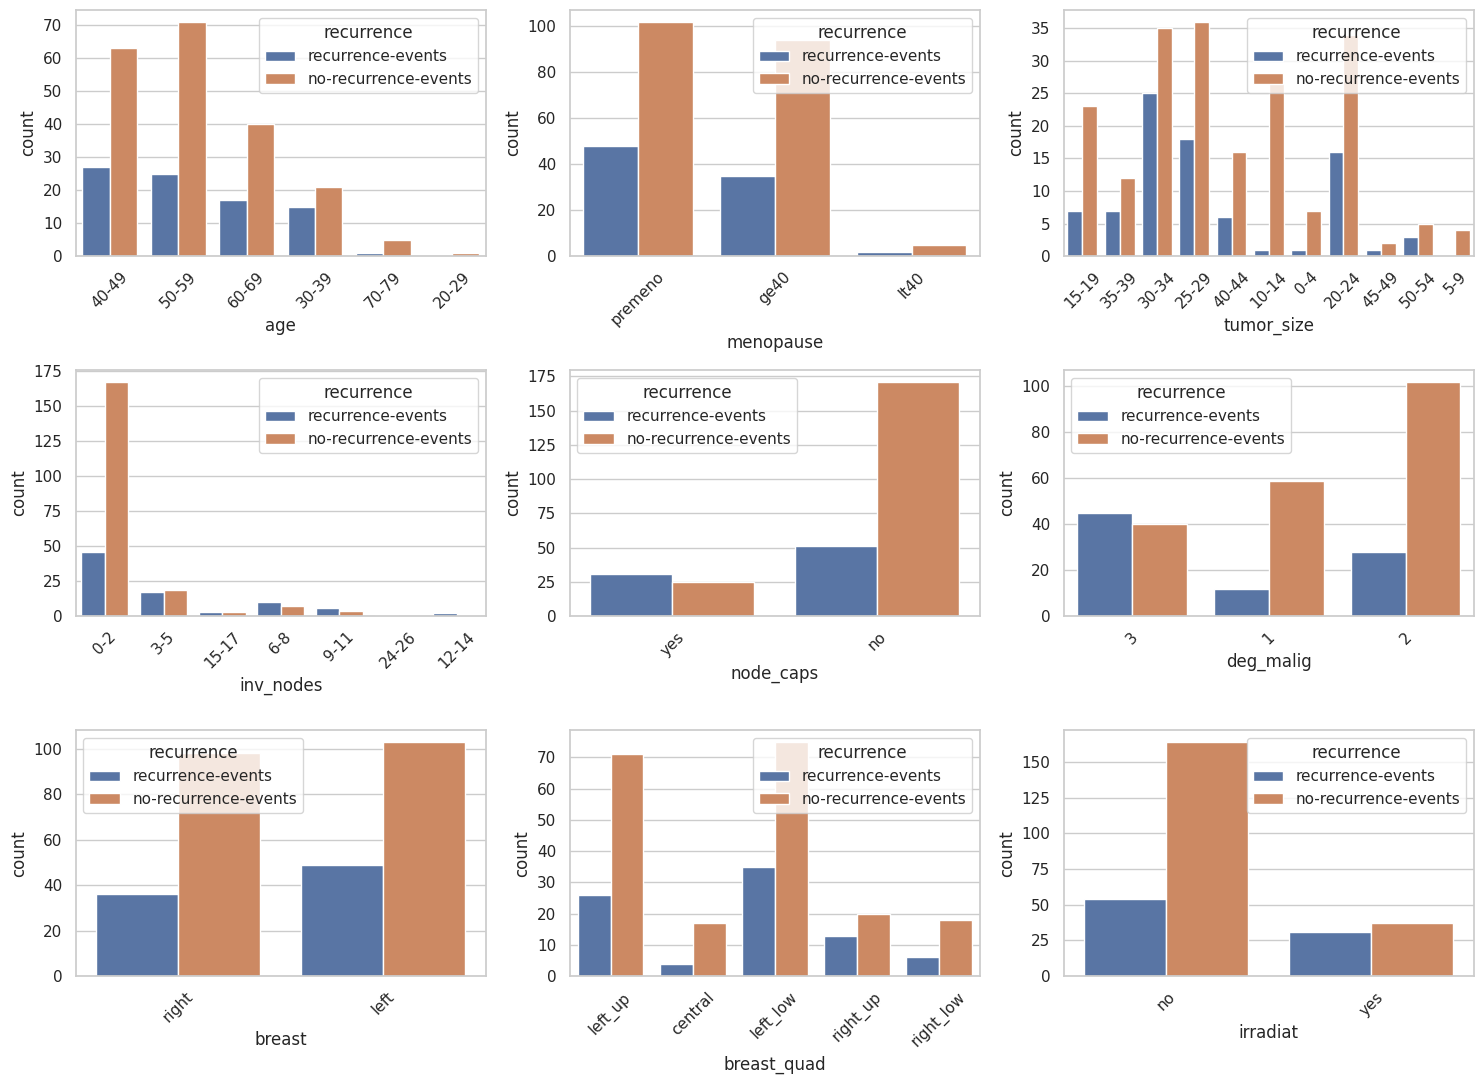

In [5]:
# Cell 5
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), df.columns.drop("recurrence")):
    sns.countplot(data=df, x=col, hue="recurrence", ax=ax)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# Cell 6: recurrence rate inside each group
for col in ["node_caps", "deg_malig", "irradiat", "inv_nodes"]:
    rate = df.groupby(col)["recurrence"].apply(lambda s: (s == "recurrence-events").mean())
    print(rate.round(2), "\n")

node_caps
no     0.23
yes    0.55
Name: recurrence, dtype: float64 

deg_malig
1    0.17
2    0.22
3    0.53
Name: recurrence, dtype: float64 

irradiat
no     0.25
yes    0.46
Name: recurrence, dtype: float64 

inv_nodes
0-2      0.22
12-14    0.67
15-17    0.50
24-26    1.00
3-5      0.47
6-8      0.59
9-11     0.60
Name: recurrence, dtype: float64 



## phase 3 : preprocessing


In [7]:
# Cell 7: split BEFORE any imputing or encoding (avoids data leakage)
from sklearn.model_selection import train_test_split

X = df.drop(columns="recurrence")
y = (df["recurrence"] == "recurrence-events").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Recurrences in test set:", y_test.sum())

(228, 9) (58, 9)
0.298 0.293
Recurrences in test set: 17


In [8]:
# Cell 8: preprocessing + model in one pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

ordinal_cols = ["age", "tumor_size", "inv_nodes", "deg_malig"]                  # ordered bands
nominal_cols = ["menopause", "node_caps", "breast", "breast_quad", "irradiat"]  # no natural order

# order of each band, smallest to largest (alphabetical would be wrong: "10-14" sorts before "5-9")
band_order = [
    ["20-29", "30-39", "40-49", "50-59", "60-69", "70-79"],                                           # age
    ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54"],  # tumor_size
    ["0-2", "3-5", "6-8", "9-11", "12-14", "15-17", "24-26"],                                         # inv_nodes
    ["1", "2", "3"],                                                                                  # deg_malig
]

preprocess = ColumnTransformer([
    ("ordinal", Pipeline([
        ("encode", OrdinalEncoder(categories=band_order)),    # bands -> 0, 1, 2, ...
        ("scale", StandardScaler()),                          # same scale for all
    ]), ordinal_cols),
    ("nominal", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),                    # fill missing with most common value
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),   # categories -> 0/1 columns
    ]), nominal_cols),
])

pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])

pipe.fit(X_train, y_train)    # quick check that everything runs
print(pipe.named_steps["prep"].transform(X_train).shape)
print(pipe.score(X_train, y_train), pipe.score(X_test, y_test))

(228, 15)
0.7675438596491229 0.6551724137931034


## Phase 4: Baseline ANd LOgistic REgression

In [9]:
# Cell 9 (no output, it only defines things)
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

def evaluate(model, X_data, y_data, threshold=0.5):
    proba = model.predict_proba(X_data)[:, 1]       # probability of recurrence
    pred = (proba >= threshold).astype(int)         # probability -> 0/1
    return {
        "accuracy": accuracy_score(y_data, pred),
        "precision": precision_score(y_data, pred, zero_division=0),
        "recall": recall_score(y_data, pred, zero_division=0),
        "f1": f1_score(y_data, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_data, proba),
        "pr_auc": average_precision_score(y_data, proba),
    }

In [10]:
# Cell 10: baseline vs logistic regression
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
log_reg = clone(pipe).fit(X_train, y_train)

pd.DataFrame({
    "Dummy (always no recurrence)": evaluate(dummy, X_test, y_test),
    "Logistic Regression": evaluate(log_reg, X_test, y_test),
}).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (always no recurrence),0.707,0.000,0.000,0.000,0.500,0.293
Logistic Regression,0.655,0.286,0.118,0.167,0.604,0.409


## Phase 5: Evaluation

True Negatives  (no recurrence, predicted no recurrence): 36
False Positives (no recurrence, predicted recurrence):    5
False Negatives (recurrence, predicted no recurrence):    15
True Positives  (recurrence, predicted recurrence):       2


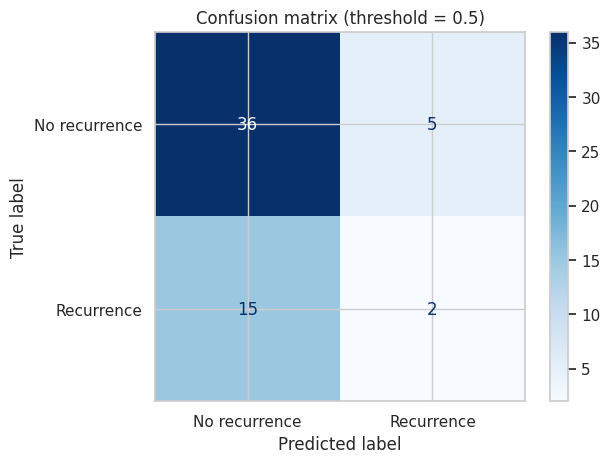

               precision    recall  f1-score   support

No recurrence       0.71      0.88      0.78        41
   Recurrence       0.29      0.12      0.17        17

     accuracy                           0.66        58
    macro avg       0.50      0.50      0.47        58
 weighted avg       0.58      0.66      0.60        58



In [11]:
# Cell 11: confusion matrix
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"True Negatives  (no recurrence, predicted no recurrence): {tn}")
print(f"False Positives (no recurrence, predicted recurrence):    {fp}")
print(f"False Negatives (recurrence, predicted no recurrence):    {fn}")
print(f"True Positives  (recurrence, predicted recurrence):       {tp}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No recurrence", "Recurrence"], cmap="Blues")
plt.title("Confusion matrix (threshold = 0.5)")
plt.show()
print(classification_report(y_test, y_pred, target_names=["No recurrence", "Recurrence"]))

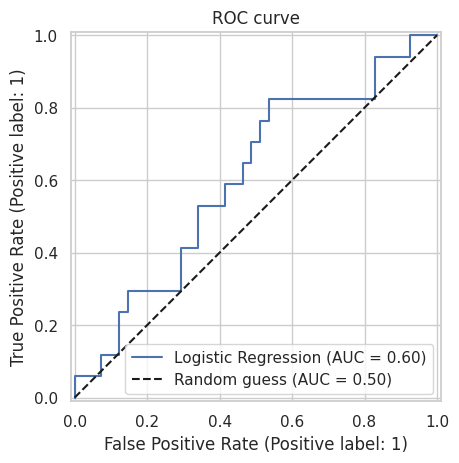

ROC-AUC: 0.604
threshold=0.2: recall=0.82  FPR=0.59  precision=0.37
threshold=0.3: recall=0.53  FPR=0.34  precision=0.39
threshold=0.5: recall=0.12  FPR=0.12  precision=0.29


In [12]:
# Cell 12: ROC curve
RocCurveDisplay.from_predictions(y_test, y_proba, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.50)")
plt.title("ROC curve")
plt.legend()
plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

for t in [0.2, 0.3, 0.5]:      # each ROC point is one threshold
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, (y_proba >= t).astype(int)).ravel()
    print(f"threshold={t}: recall={tp_/(tp_+fn_):.2f}  FPR={fp_/(fp_+tn_):.2f}  precision={tp_/max(tp_+fp_, 1):.2f}")

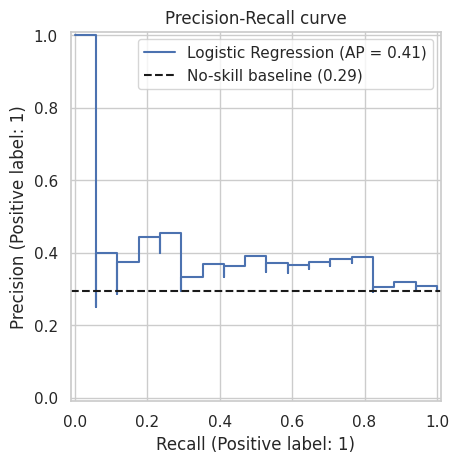

Average precision (PR-AUC): 0.409


In [13]:
# Cell 13: Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="Logistic Regression")
plt.axhline(y_test.mean(), color="k", linestyle="--", label=f"No-skill baseline ({y_test.mean():.2f})")
plt.title("Precision-Recall curve")
plt.legend()
plt.show()
print("Average precision (PR-AUC):", round(average_precision_score(y_test, y_proba), 3))

## Phase 6: Overfitting and underfitting

In [14]:
# Cell 14: train vs test
gap = pd.DataFrame({"Train": evaluate(log_reg, X_train, y_train),
                    "Test": evaluate(log_reg, X_test, y_test)})
gap["Gap (train - test)"] = gap["Train"] - gap["Test"]
gap.round(3)

,Train,Test,Gap (train - test)
accuracy,0.768,0.655,0.112
precision,0.674,0.286,0.389
recall,0.426,0.118,0.309
f1,0.523,0.167,0.356
roc_auc,0.759,0.604,0.155
pr_auc,0.631,0.409,0.222


In [15]:
# Cell 15: 5-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "recall", "f1", "roc_auc"]
cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)

pd.DataFrame({m: {"train mean": cv_res[f"train_{m}"].mean(),
                  "validation mean": cv_res[f"test_{m}"].mean(),
                  "validation std": cv_res[f"test_{m}"].std()} for m in scoring}).T.round(3)

,train mean,validation mean,validation std
accuracy,0.763,0.719,0.044
recall,0.401,0.353,0.025
f1,0.502,0.431,0.042
roc_auc,0.771,0.686,0.035


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

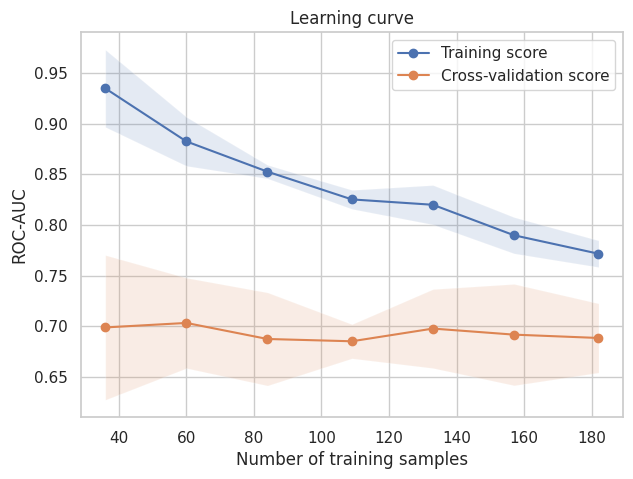

In [16]:
# Cell 16: learning curve (plot only)
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(
    pipe, X_train, y_train, cv=cv, scoring="roc_auc", train_sizes=np.linspace(0.2, 1.0, 7))

plt.figure(figsize=(7, 5))
for scores, label in [(train_sc, "Training score"), (val_sc, "Cross-validation score")]:
    m, s = scores.mean(axis=1), scores.std(axis=1)
    plt.plot(sizes, m, "o-", label=label)
    plt.fill_between(sizes, m - s, m + s, alpha=0.15)
plt.xlabel("Number of training samples")
plt.ylabel("ROC-AUC")
plt.title("Learning curve")
plt.legend()
plt.show()

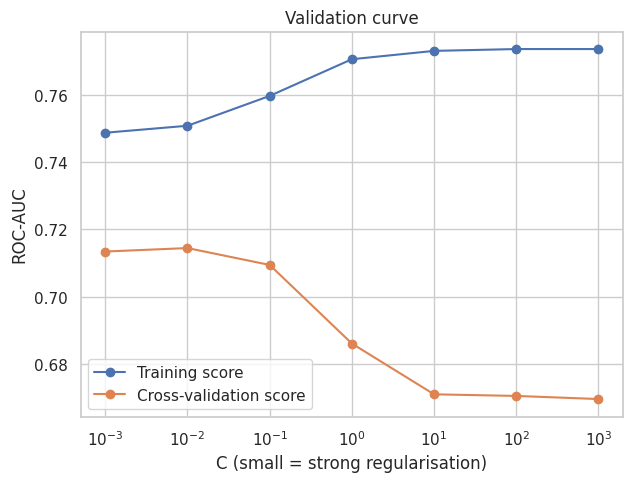

In [17]:
# Cell 17: validation curve for C (plot only)
from sklearn.model_selection import validation_curve

C_range = np.logspace(-3, 3, 7)
train_vc, val_vc = validation_curve(
    pipe, X_train, y_train, param_name="model__C", param_range=C_range, cv=cv, scoring="roc_auc")

plt.figure(figsize=(7, 5))
plt.semilogx(C_range, train_vc.mean(axis=1), "o-", label="Training score")
plt.semilogx(C_range, val_vc.mean(axis=1), "o-", label="Cross-validation score")
plt.xlabel("C (small = strong regularisation)")
plt.ylabel("ROC-AUC")
plt.title("Validation curve")
plt.legend()
plt.show()

,train AUC,validation AUC,gap
model,,,
Underfit (1 weak feature),0.559,0.558,0.001
"Good fit (all features, C=0.01)",0.751,0.714,0.036
"Default (all features, C=1)",0.771,0.686,0.085
"Overfit (interactions, C=1000)",0.985,0.598,0.387


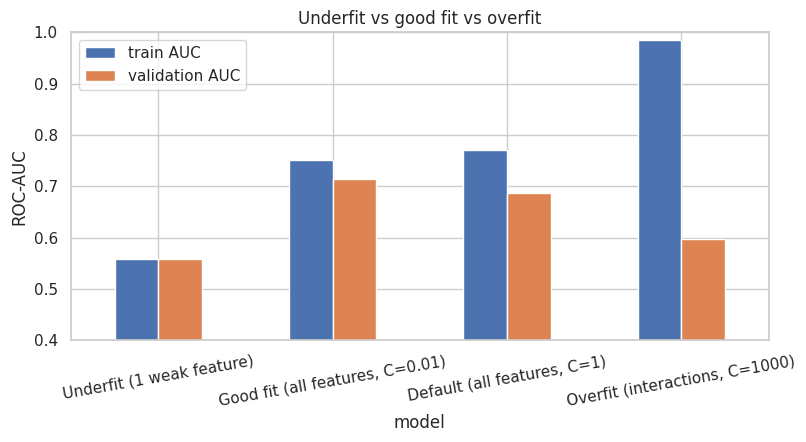

In [18]:
# Cell 18: underfit vs good fit vs overfit
from sklearn.preprocessing import PolynomialFeatures

underfit = Pipeline([      # one weak feature only
    ("prep", ColumnTransformer([("nominal", OneHotEncoder(drop="if_binary"), ["breast"])])),
    ("model", LogisticRegression(max_iter=1000)),
])
overfit = Pipeline([       # all pairwise interactions (15 -> 135 features), no regularisation
    ("prep", preprocess),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=1000, max_iter=5000)),
])

experiments = {
    "Underfit (1 weak feature)": underfit,
    "Good fit (all features, C=0.01)": clone(pipe).set_params(model__C=0.01),
    "Default (all features, C=1)": clone(pipe),
    "Overfit (interactions, C=1000)": overfit,
}

rows = []
for name, model in experiments.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring="roc_auc", return_train_score=True)
    rows.append({"model": name, "train AUC": r["train_score"].mean(), "validation AUC": r["test_score"].mean()})

fit_table = pd.DataFrame(rows).set_index("model")
fit_table["gap"] = fit_table["train AUC"] - fit_table["validation AUC"]
display(fit_table.round(3))

fit_table[["train AUC", "validation AUC"]].plot(kind="bar", figsize=(9, 4), ylim=(0.4, 1.0), rot=10)
plt.ylabel("ROC-AUC")
plt.title("Underfit vs good fit vs overfit")
plt.show()

## Phase 7: Improve and interpret

In [19]:
# Cell 19: tune C
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(pipe, {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, cv=cv, scoring="roc_auc")
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validated ROC-AUC:", round(grid.best_score_, 3))
best_model = grid.best_estimator_
pd.DataFrame(grid.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(4)


Best parameters: {'model__C': 0.01}
Best cross-validated ROC-AUC: 0.714


,param_model__C,mean_test_score,std_test_score
0,0.01,0.7145,0.0412
1,0.03,0.7081,0.0322
2,0.10,0.7095,0.0386
3,0.30,0.6970,0.0384
4,1.00,0.6861,0.0349
5,3.00,0.6729,0.0428
6,10.00,0.6710,0.0430


In [20]:
# Cell 20: handle class imbalance
balanced_model = clone(best_model).set_params(model__class_weight="balanced").fit(X_train, y_train)

p_tuned = best_model.predict_proba(X_test)[:, 1]
p_bal = balanced_model.predict_proba(X_test)[:, 1]
print("Tuned model:    highest predicted probability =", p_tuned.max().round(2))
print("Balanced model: highest predicted probability =", p_bal.max().round(2))

Tuned model:    highest predicted probability = 0.44
Balanced model: highest predicted probability = 0.65


In [21]:
# Cell 21: compare all models on the untouched test set
pd.DataFrame({
    "Dummy baseline": evaluate(dummy, X_test, y_test),
    "LogReg default (C=1)": evaluate(log_reg, X_test, y_test),
    "LogReg tuned C": evaluate(best_model, X_test, y_test),
    "LogReg tuned C + balanced": evaluate(balanced_model, X_test, y_test),
}).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy baseline,0.707,0.000,0.000,0.000,0.500,0.293
LogReg default (C=1),0.655,0.286,0.118,0.167,0.604,0.409
LogReg tuned C,0.707,0.000,0.000,0.000,0.669,0.531
LogReg tuned C + balanced,0.586,0.348,0.471,0.400,0.671,0.536


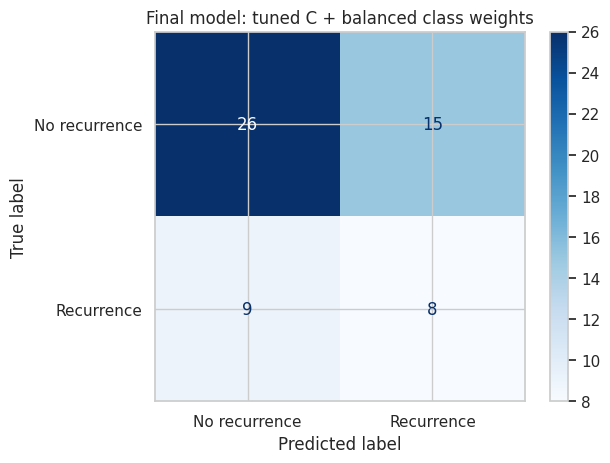

               precision    recall  f1-score   support

No recurrence       0.74      0.63      0.68        41
   Recurrence       0.35      0.47      0.40        17

     accuracy                           0.59        58
    macro avg       0.55      0.55      0.54        58
 weighted avg       0.63      0.59      0.60        58



In [22]:
# Cell 22: confusion matrix of the final model
final_model = balanced_model
y_final = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_final, display_labels=["No recurrence", "Recurrence"], cmap="Blues")
plt.title("Final model: tuned C + balanced class weights")
plt.show()
print(classification_report(y_test, y_final, target_names=["No recurrence", "Recurrence"]))

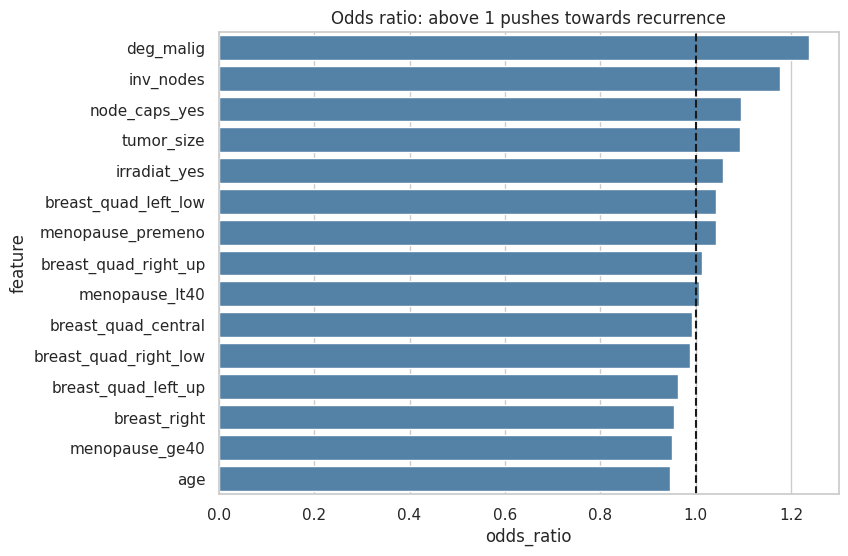

,feature,coefficient,odds_ratio
0,deg_malig,0.214,1.239
1,inv_nodes,0.164,1.178
2,node_caps_yes,0.092,1.096
3,tumor_size,0.090,1.094
4,irradiat_yes,0.056,1.057
5,breast_quad_left_low,0.043,1.043
6,menopause_premeno,0.042,1.043
7,breast_quad_right_up,0.014,1.014
8,menopause_lt40,0.008,1.008
9,breast_quad_central,-0.007,0.994


In [23]:
# Cell 23: which features push towards recurrence?
names = [n.split("__")[1] for n in final_model.named_steps["prep"].get_feature_names_out()]
coefs = final_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({"feature": names, "coefficient": coefs, "odds_ratio": np.exp(coefs)})
coef_df = coef_df.sort_values("coefficient", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, y="feature", x="odds_ratio", color="steelblue")
plt.axvline(1, color="k", linestyle="--")
plt.title("Odds ratio: above 1 pushes towards recurrence")
plt.show()
coef_df.round(3)

In [24]:
# Cell 24: predict for a new patient
new_patient = pd.DataFrame([{
    "age": "50-59", "menopause": "premeno", "tumor_size": "25-29", "inv_nodes": "3-5",
    "node_caps": "yes", "deg_malig": "3", "breast": "left", "breast_quad": "left_up",
    "irradiat": "yes"}])

prob = final_model.predict_proba(new_patient)[0, 1]
label = "Recurrence (high risk)" if prob >= 0.5 else "No recurrence (low risk)"
print(f"Predicted probability of recurrence: {prob:.2f}  ->  {label}")

Predicted probability of recurrence: 0.60  ->  Recurrence (high risk)
